In [56]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [23]:
from tensorflow.keras.models import Sequential
#this lets me build neural network layer by layer in keras
from tensorflow.keras.layers import Dense #dense makes the final prediction
from tensorflow.keras.layers import Conv2D #conv2d extract features
from tensorflow.keras.layers import Flatten #flatter reshape kore

from tensorflow.keras.layers import MaxPool2D #maxpooling kore- size reduce
from tensorflow.keras.layers import Dropout 

from tensorflow.keras.utils import to_categorical #converts numerical into labels into one hot encoding format


In [ ]:
# import kagglehub


# path = kagglehub.dataset_download("oddrationale/mnist-in-csv")

# print("Path to dataset files:", path)
# import os

# print("Downloaded files:")
# for filename in sorted(os.listdir(path)):
#     print(filename)

In [26]:
train_file = os.path.join(path, "mnist_train.csv")
test_file = os.path.join(path, "mnist_test.csv")
df = pd.read_csv(train_file)
df_test= pd.read_csv(test_file)




In [27]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [28]:
df.shape

(60000, 785)

In [29]:
#pre-process
X_train = df.drop("label",axis=1).values
y_train = df['label'].values
X_test=df_test.drop('label',axis=1).values
y_test = df_test['label'].values

In [30]:
X_train=X_train.astype('float32')/255.0
X_test=X_test.astype('float32')/255.0

In [31]:
XtrainImage = X_train.reshape(-1,28,28)
XtestImage = X_test.reshape(-1,28,28)

In [32]:
y_train_cat= to_categorical(y_train,10)
ytestcat= to_categorical(y_test,10)

# First try perceptron model

In [33]:
perceptron= Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10,activation='softmax')
])

In [34]:
perceptron.compile(optimizer='sgd',loss='categorical_crossentropy',metrics=['accuracy'])

In [35]:
history_percp=perceptron.fit(XtrainImage,y_train_cat ,epochs=5,
    batch_size=32,validation_data=(XtestImage, ytestcat),verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8159 - loss: 0.7782 - val_accuracy: 0.8789 - val_loss: 0.4822
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8801 - loss: 0.4574 - val_accuracy: 0.8951 - val_loss: 0.4024
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8906 - loss: 0.4045 - val_accuracy: 0.9018 - val_loss: 0.3690
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8966 - loss: 0.3781 - val_accuracy: 0.9057 - val_loss: 0.3499
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9004 - loss: 0.3612 - val_accuracy: 0.9097 - val_loss: 0.3376


In [36]:
accuracy_perceptron = perceptron.evaluate(XtestImage,ytestcat,verbose=0)[1]
accuracy_perceptron

0.9096999764442444

# Now lets try ANN

In [38]:
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation='relu'),
    Dense(64,activation='relu'),
    Dense(10,activation='softmax')
])

In [39]:
ann.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])


In [40]:
ann_model= ann.fit(XtrainImage,y_train_cat, epochs=5,
                    batch_size=32, validation_data=(XtestImage,ytestcat),verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9300 - loss: 0.2387 - val_accuracy: 0.9655 - val_loss: 0.1088
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9693 - loss: 0.1007 - val_accuracy: 0.9731 - val_loss: 0.0895
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9782 - loss: 0.0709 - val_accuracy: 0.9744 - val_loss: 0.0831
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9826 - loss: 0.0543 - val_accuracy: 0.9766 - val_loss: 0.0790
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9858 - loss: 0.0435 - val_accuracy: 0.9737 - val_loss: 0.0880


In [42]:
acc_ann=ann.evaluate(XtestImage,ytestcat,verbose=0)[1]
acc_ann

0.9736999869346619

# Convolutional neural network

In [43]:
X_train_cnn = X_train.reshape(-1, 28, 28,1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

In [45]:
cnn = Sequential([
    Conv2D(32,kernel_size=(3,3),activation='relu',input_shape=(28,28,1)),
    MaxPool2D(pool_size=(2,2)),
    Conv2D(64,kernel_size=(3,3),activation='relu'),
    MaxPool2D(pool_size=(2,2)),
    Flatten(),
    Dense(128,activation='relu'),
    Dropout(0.5),
    Dense(10,activation='softmax')
])

In [46]:
cnn.compile(optimizer='adam',loss="categorical_crossentropy",metrics=['accuracy'])

In [47]:
cnn_model= cnn.fit(X_train_cnn,y_train_cat, epochs=5, validation_data=(X_test_cnn,ytestcat) 
                   , verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 63s 33ms/step - accuracy: 0.9351 - loss: 0.2094 - val_accuracy: 0.9836 - val_loss: 0.0499
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 61s 32ms/step - accuracy: 0.9770 - loss: 0.0786 - val_accuracy: 0.9883 - val_loss: 0.0362
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 64s 34ms/step - accuracy: 0.9836 - loss: 0.0572 - val_accuracy: 0.9884 - val_loss: 0.0307
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 62s 33ms/step - accuracy: 0.9860 - loss: 0.0465 - val_accuracy: 0.9911 - val_loss: 0.0276
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9882 - loss: 0.0390 - val_accuracy: 0.9901 - val_loss: 0.0297


In [48]:
acc_cnn = cnn.evaluate(X_test_cnn,ytestcat, verbose=0)[1]
acc_cnn

0.9901000261306763

In [57]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

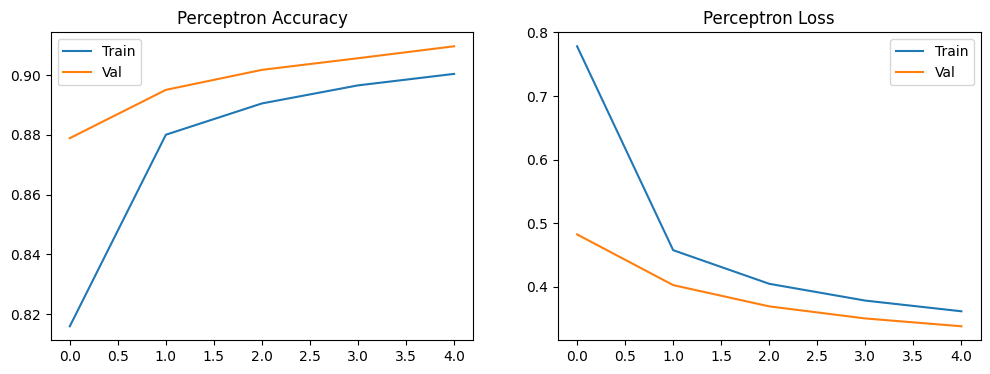

In [58]:
plot_training(history_percp, "Perceptron")

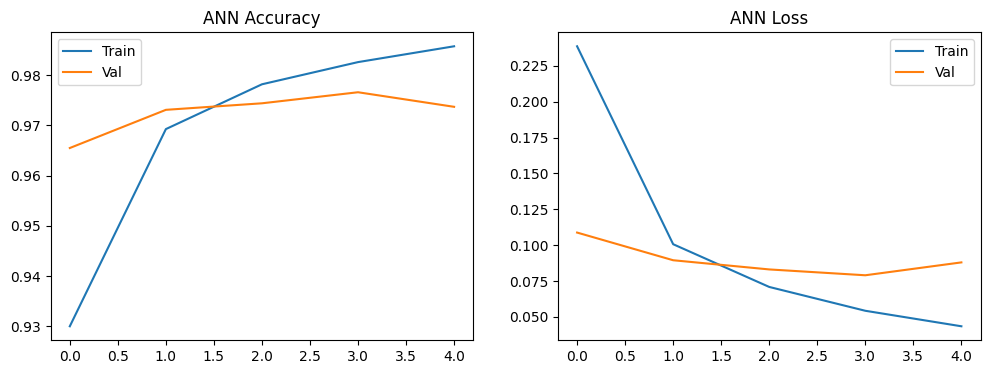

In [59]:
plot_training(ann_model, "ANN")

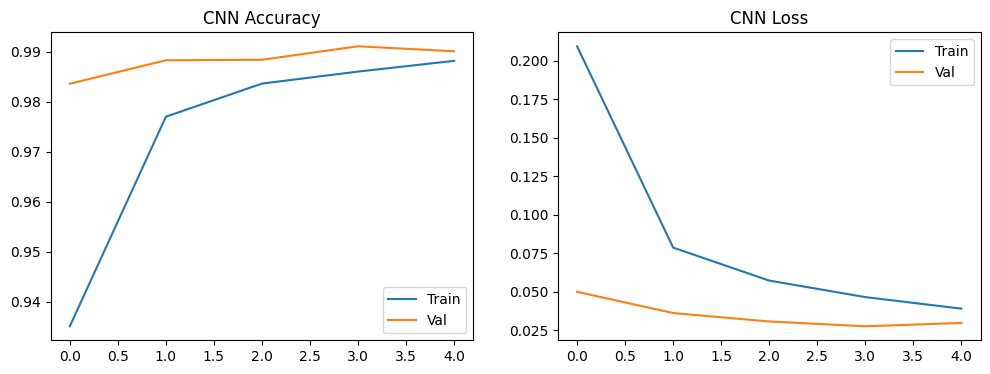

In [60]:
plot_training(cnn_model, "CNN")

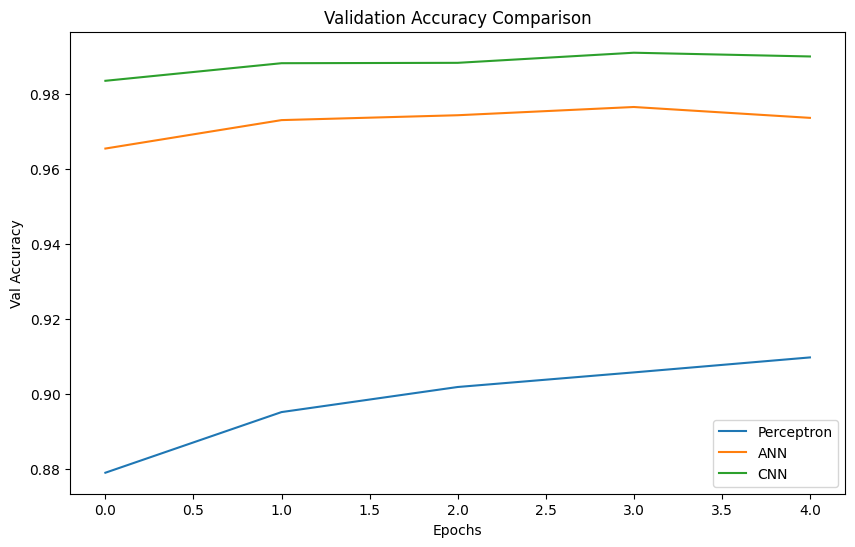

In [62]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(ann_model.history['val_accuracy'], label="ANN")
plt.plot(cnn_model.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [63]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


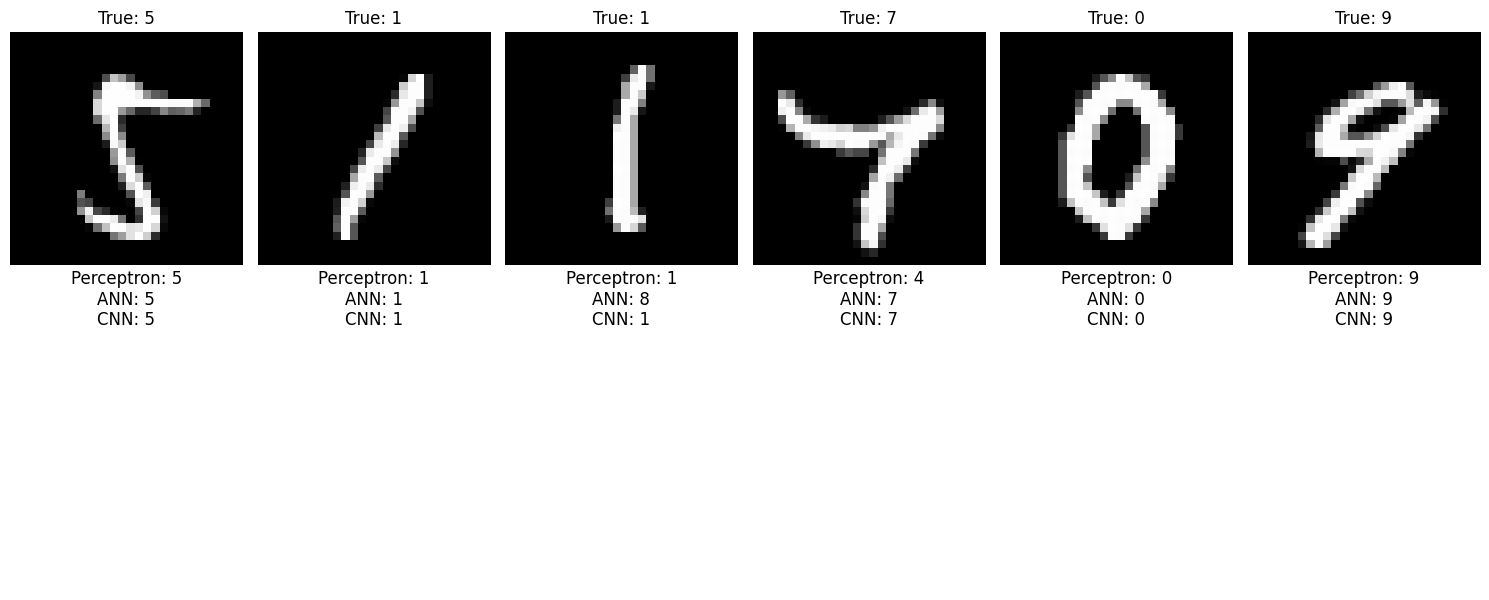

In [69]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], XtestImage, X_test_cnn, y_test, 6)